<a href="https://colab.research.google.com/github/Nyamu007/Completed-Projects/blob/main/t21nov_depthest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import polars  as

In [ ]:
import random
from datasets import load_dataset

# Stream without downloading the full dataset to disk
streamed_ds = load_dataset(
    "sayakpaul/nyu_depth_v2",
    split="train",
    streaming=True,
)

# Deterministic ~10% sampling on the fly
rng = random.Random(42)
sample_rate = 0.10
sampled_batches = []

for sample in streamed_ds:
    if rng.random() < sample_rate:
        rgb_img = sample["image"]       # PIL Image (RGB)
        depth_map = sample["depth_map"] # PIL Image (depth)
        sampled_batches.append((rgb_img, depth_map))

print(f"Sampled {len(sampled_batches)} pairs (~10% of split)")

README.md:   0%|          | 0.00/8.71k [00:00<?, ?B/s]

nyu_depth_v2.py:   0%|          | 0.00/3.84k [00:00<?, ?B/s]

RuntimeError: Dataset scripts are no longer supported, but found nyu_depth_v2.py

In [ ]:
import random
from datasets import load_dataset

# Stream a Parquet-backed NYU Depth V2 dataset without full download
streamed_ds = load_dataset(
    "vikhyatk/nyu_depth_v2",
    split="train",
    streaming=True,
)

rng = random.Random(42)
sample_rate = 0.10
sampled_pairs = []

for row in streamed_ds:
    if rng.random() < sample_rate:
        # Inspect available keys on first match if needed: print(row.keys())
        sampled_pairs.append(row)

print(f"Sampled {len(sampled_pairs)} rows (~10% of stream)")

README.md:   0%|          | 0.00/615 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/157 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/157 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import torch
from torch.utils.data import IterableDataset, DataLoader

class StreamedDepthDistillDataset(IterableDataset):
    "vikhyatk/nyu_depth_v2",
    def __init__(self, hf_dataset_name="vikhyatk/nyu_depth_v2", split="train", sample_prob=0.10, seed=42):
        self.hf_dataset_name = hf_dataset_name
        self.split = split
        self.sample_prob = sample_prob
        self.seed = seed

    def __iter__(self):
        rng = random.Random(self.seed)
        ds = load_dataset(self.hf_dataset_name, split=self.split, streaming=True)
        for item in ds:
            if rng.random() <= self.sample_prob:
                yield item["image"], item["depth_map"]

train_stream = StreamedDepthDistillDataset(sample_prob=0.10)
loader = DataLoader(train_stream, batch_size=4)

for batch_idx, (rgbs, gt_depths) in enumerate(loader):
    # 1. Run frozen teacher model on `rgbs` to get teacher depth predictions
    # 2. Run student model on `rgbs` and compute loss against teacher + `gt_depths`
    if batch_idx == 2:
        break

In [ ]:
import random
from datasets import load_dataset

streamed_ds = load_dataset(
    "vikhyatk/nyu_depth_v2",
    split="train",
    streaming=True,
)

rng = random.Random(42)
sample_rate = 0.10
target_samples = 150   # Stop once you have enough pairs
max_rows_scanned = 2000  # Safety cap so it never runs endlessly
sampled_pairs = []

for seen, row in enumerate(streamed_ds, start=1):
    if rng.random() < sample_rate:
        sampled_pairs.append(row)
        if len(sampled_pairs) % 25 == 0:
            print(f"Scanned {seen} rows | Collected {len(sampled_pairs)}/{target_samples} samples")

    if len(sampled_pairs) >= target_samples or seen >= max_rows_scanned:
        break

print(f"Done. Scanned {seen} rows, sampled {len(sampled_pairs)} pairs.")

Resolving data files:   0%|          | 0/157 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/157 [00:00<?, ?it/s]

Scanned 208 rows | Collected 25/150 samples
Scanned 505 rows | Collected 50/150 samples
Scanned 818 rows | Collected 75/150 samples
Scanned 1062 rows | Collected 100/150 samples
Scanned 1262 rows | Collected 125/150 samples
Scanned 1539 rows | Collected 150/150 samples
Done. Scanned 1539 rows, sampled 150 pairs.


In [ ]:
for i, row in enumerate(streamed_ds, start=1):
    if i == 1:
        print("First row keys:", list(row.keys()))
    if i % 100 == 0:
        print(f"Streamed {i} rows...")
    if i >= 300:
        break

First row keys: ['image', 'depth_map']
Streamed 100 rows...
Streamed 200 rows...
Streamed 300 rows...


# Inspect depth_map Format

In [ ]:
import numpy as np

sample = samples[0]
rgb = sample["image"]
depth_pil = sample["depth_map"]
depth_np = np.array(depth_pil)

print("RGB size & mode:", rgb.size, rgb.mode)
print("Depth PIL mode & size:", depth_pil.mode, depth_pil.size)
print("Depth array shape, dtype:", depth_np.shape, depth_np.dtype)
print("Depth min / median / max:", np.nanmin(depth_np), np.nanmedian(depth_np), np.nanmax(depth_np))
print("Zero/invalid pixel fraction:", np.mean((depth_np <= 0) | np.isnan(depth_np)))

NameError: name 'samples' is not defined

In [ ]:
import random
import numpy as np
from datasets import load_dataset

streamed_ds = load_dataset(
    "vikhyatk/nyu_depth_v2",
    split="train",
    streaming=True,
)

rng = random.Random(42)
sample_rate = 0.10
target_samples = 200
max_rows_scanned = 3000
samples = []

for seen, row in enumerate(streamed_ds, start=1):
    if rng.random() < sample_rate:
        samples.append({
            "image": row["image"],
            "depth_map": row["depth_map"],
        })
        if len(samples) % 25 == 0:
            print(f"Scanned {seen} rows | Sampled {len(samples)}/{target_samples} pairs")

    if len(samples) >= target_samples or seen >= max_rows_scanned:
        break

print(f"Collected {len(samples)} samples.")

# Inspect first sample
sample = samples[0]
rgb = sample["image"]
depth_pil = sample["depth_map"]
depth_np = np.array(depth_pil)

print("RGB size & mode:", rgb.size, rgb.mode)
print("Depth PIL mode & size:", depth_pil.mode, depth_pil.size)
print("Depth array shape, dtype:", depth_np.shape, depth_np.dtype)
print("Depth min / median / max:", np.nanmin(depth_np), np.nanmedian(depth_np), np.nanmax(depth_np))
print("Zero/invalid pixel fraction:", np.mean((depth_np <= 0) | np.isnan(depth_np)))

Resolving data files:   0%|          | 0/157 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/157 [00:00<?, ?it/s]

Scanned 208 rows | Sampled 25/200 pairs
Scanned 505 rows | Sampled 50/200 pairs
Scanned 818 rows | Sampled 75/200 pairs
Scanned 1062 rows | Sampled 100/200 pairs
Scanned 1262 rows | Sampled 125/200 pairs
Scanned 1539 rows | Sampled 150/200 pairs
Scanned 1878 rows | Sampled 175/200 pairs
Scanned 2127 rows | Sampled 200/200 pairs
Collected 200 samples.
RGB size & mode: (640, 480) RGB
Depth PIL mode & size: F (640, 480)
Depth array shape, dtype: (480, 640) float32
Depth min / median / max: 0.0 3.2107453 6.656423
Zero/invalid pixel fraction: 0.029778645833333332


Run Teacher Pseudo-Labels

In [ ]:
import torch
import numpy as np
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

device = "cuda" if torch.cuda.is_available() else "cpu"
teacher_id = "depth-anything/Depth-Anything-V2-Small-hf"

processor = AutoImageProcessor.from_pretrained(teacher_id)
teacher = AutoModelForDepthEstimation.from_pretrained(teacher_id).to(device).eval()

for item in samples:
    rgb = item["image"].convert("RGB")
    inputs = processor(images=rgb, return_tensors="pt").to(device)

    with torch.no_grad():
        pred = teacher(**inputs).predicted_depth
        teacher_depth = torch.nn.functional.interpolate(
            pred.unsqueeze(1),
            size=rgb.size[::-1],  # (H, W)
            mode="bicubic",
            align_corners=False,
        ).squeeze().cpu().numpy().astype(np.float32)

    item["teacher_depth"] = teacher_depth

print("Teacher pseudo-depth shape:", samples[0]["teacher_depth"].shape, samples[0]["teacher_depth"].dtype)

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

KeyboardInterrupt: 

Save Tiny Subset to Disk

In [ ]:
from pathlib import Path
import numpy as np

out_dir = Path("nyu_10pct_subset")
out_dir.mkdir(parents=True, exist_ok=True)

target_size = (256, 192)  # (W, H) for small disk footprint; use None to keep original size

for idx, item in enumerate(samples):
    rgb = item["image"].convert("RGB")
    gt_depth = np.array(item["depth_map"])

    if target_size is not None:
        rgb_save = rgb.resize(target_size)
        # Resize depth cleanly via PIL or nearest/bilinear interpolation
        depth_pil = item["depth_map"].resize(target_size)
        gt_save = np.array(depth_pil)
    else:
        rgb_save = rgb
        gt_save = gt_depth

    rgb_save.save(out_dir / f"{idx:04d}_rgb.jpg", quality=90)
    payload = {"gt_depth": gt_save}
    if "teacher_depth" in item:
        t_depth = item["teacher_depth"]
        if target_size is not None:
            import torch
            t_depth = torch.nn.functional.interpolate(
                torch.from_numpy(t_depth)[None, None],
                size=(target_size[1], target_size[0]),
                mode="bilinear",
                align_corners=False,
            ).squeeze().numpy().astype(np.float32)
        payload["teacher_depth"] = t_depth

    np.savez_compressed(out_dir / f"{idx:04d}_depth.npz", **payload)

total_mb = sum(f.stat().st_size for f in out_dir.iterdir()) / (1024 * 1024)
print(f"Saved {len(samples)} pairs to '{out_dir}' ({total_mb:.2f} MB total)")

Saved 200 pairs to 'nyu_10pct_subset' (40.18 MB total)


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


def align_scale_and_shift(pred: torch.Tensor, target: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    """Align `pred` to `target` via least-squares scale and shift over valid `mask` pixels."""
    aligned = torch.empty_like(pred)
    for i in range(pred.shape[0]):
        m = mask[i].bool().flatten()
        if m.sum() < 10:
            aligned[i] = pred[i]
            continue
        p = pred[i].flatten()[m].float()
        t = target[i].flatten()[m].float()
        design = torch.stack([p, torch.ones_like(p)], dim=1)
        scale, shift = torch.linalg.lstsq(design, t.unsqueeze(1)).solution.squeeze(1)
        aligned[i] = pred[i] * scale + shift
    return aligned


class DepthDistillationLoss(nn.Module):
    def __init__(self, alpha_gt: float = 1.0, alpha_teacher: float = 0.5, align_teacher: bool = True):
        super().__init__()
        self.alpha_gt = alpha_gt
        self.alpha_teacher = alpha_teacher
        self.align_teacher = align_teacher

    def forward(
        self,
        pred: torch.Tensor,     # [B, 1, H, W]
        gt: torch.Tensor,       # [B, 1, H, W]
        teacher: torch.Tensor,  # [B, 1, H, W]
    ) -> dict[str, torch.Tensor]:
        valid_gt = torch.isfinite(gt) & (gt > 0)
        valid_teacher = torch.isfinite(teacher)

        loss_gt = F.l1_loss(pred[valid_gt], gt[valid_gt]) if valid_gt.any() else pred.new_tensor(0.0)

        if valid_teacher.any() and self.alpha_teacher > 0:
            if self.align_teacher and valid_gt.any():
                joint_mask = valid_gt & valid_teacher
                teacher_target = align_scale_and_shift(teacher, gt, joint_mask)
                mask_t = joint_mask if joint_mask.any() else valid_teacher
                loss_teacher = F.l1_loss(pred[mask_t], teacher_target[mask_t])
            else:
                loss_teacher = F.l1_loss(pred[valid_teacher], teacher[valid_teacher])
        else:
            loss_teacher = pred.new_tensor(0.0)

        total_loss = self.alpha_gt * loss_gt + self.alpha_teacher * loss_teacher
        return {
            "loss": total_loss,
            "loss_gt": loss_gt.detach(),
            "loss_teacher": loss_teacher.detach(),
        }

In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF


class SavedDepthSubsetDataset(Dataset):
    def __init__(self, folder: str | Path):
        self.folder = Path(folder)
        self.rgb_files = sorted(self.folder.glob("*_rgb.jpg"))

    def __len__(self) -> int:
        return len(self.rgb_files)

    def __getitem__(self, idx: int):
        rgb_path = self.rgb_files[idx]
        npz_path = self.folder / rgb_path.name.replace("_rgb.jpg", "_depth.npz")

        rgb = Image.open(rgb_path).convert("RGB")
        rgb_tensor = TF.normalize(
            TF.to_tensor(rgb),
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        )

        data = np.load(npz_path)
        gt_depth = torch.from_numpy(data["gt_depth"]).float().unsqueeze(0)
        teacher_depth = torch.from_numpy(data["teacher_depth"]).float().unsqueeze(0)
        return rgb_tensor, gt_depth, teacher_depth


def train_student(
    model: torch.nn.Module,
    subset_dir: str | Path = "nyu_10pct_subset",
    epochs: int = 10,
    batch_size: int = 8,
    lr: float = 1e-4,
    alpha_gt: float = 1.0,
    alpha_teacher: float = 0.5,
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    dataset = SavedDepthSubsetDataset(subset_dir)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
    )

    criterion = DepthDistillationLoss(alpha_gt=alpha_gt, alpha_teacher=alpha_teacher, align_teacher=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    for epoch in range(1, epochs + 1):
        model.train()
        totals = {"loss": 0.0, "loss_gt": 0.0, "loss_teacher": 0.0}

        for rgb, gt, teacher in loader:
            rgb = rgb.to(device, non_blocking=True)
            gt = gt.to(device, non_blocking=True)
            teacher = teacher.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                pred = model(rgb)
                if pred.shape[-2:] != gt.shape[-2:]:
                    pred = F.interpolate(pred, size=gt.shape[-2:], mode="bilinear", align_corners=False)
                losses = criterion(pred, gt, teacher)
                loss = losses["loss"]

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            for key in totals:
                totals[key] += losses[key].item()

        steps = max(len(loader), 1)
        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Loss: {totals['loss']/steps:.4f} | "
            f"GT L1: {totals['loss_gt']/steps:.4f} | "
            f"Teacher L1: {totals['loss_teacher']/steps:.4f}"
        )

Edge-Aware Depth Smoothness Loss

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class EdgeAwareSmoothnessLoss(nn.Module):
    """Penalizes depth jumps in flat RGB regions while preserving sharp RGB edges."""

    def __init__(self, weight: float = 0.1):
        super().__init__()
        self.weight = weight

    def forward(self, depth: torch.Tensor, rgb: torch.Tensor) -> torch.Tensor:
        # depth: [B, 1, H, W], rgb: [B, 3, H, W]
        if depth.shape[-2:] != rgb.shape[-2:]:
            rgb = F.interpolate(rgb, size=depth.shape[-2:], mode="bilinear", align_corners=False)

        # Depth spatial gradients
        grad_depth_x = torch.abs(depth[:, :, :, :-1] - depth[:, :, :, 1:])
        grad_depth_y = torch.abs(depth[:, :, :-1, :] - depth[:, :, 1:, :])

        # RGB spatial gradients (averaged across channels)
        grad_rgb_x = torch.mean(torch.abs(rgb[:, :, :, :-1] - rgb[:, :, :, 1:]), dim=1, keepdim=True)
        grad_rgb_y = torch.mean(torch.abs(rgb[:, :, :-1, :] - rgb[:, :, 1:, :]), dim=1, keepdim=True)

        # Edge weights: close to 1 on flat surfaces, near 0 on strong RGB edges
        weights_x = torch.exp(-grad_rgb_x)
        weights_y = torch.exp(-grad_rgb_y)

        loss_x = (grad_depth_x * weights_x).mean()
        loss_y = (grad_depth_y * weights_y).mean()
        return self.weight * (loss_x + loss_y)

Evaluate Depth Accuracy

In [ ]:
import torch
import torch.nn.functional as F


@torch.no_grad()
def evaluate_depth_metrics(
    model: torch.nn.Module,
    val_loader: torch.utils.data.DataLoader,
    device: torch.device | None = None,
) -> dict[str, float]:
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model.eval()
    model.to(device)

    abs_rel_sum = 0.0
    sq_err_sum = 0.0
    delta1_hits = 0
    total_valid_pixels = 0

    for batch in val_loader:
        rgb, gt = batch[0], batch[1]
        rgb = rgb.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)

        pred = model(rgb)
        if pred.shape[-2:] != gt.shape[-2:]:
            pred = F.interpolate(pred, size=gt.shape[-2:], mode="bilinear", align_corners=False)

        pred = pred.float().clamp(min=1e-4)
        gt_f = gt.float()

        valid = torch.isfinite(gt_f) & (gt_f > 0) & torch.isfinite(pred)
        if not valid.any():
            continue

        p = pred[valid]
        g = gt_f[valid]

        abs_rel_sum += torch.abs(p - g).div(g).sum().item()
        sq_err_sum += ((p - g) ** 2).sum().item()

        ratio = torch.maximum(g / p, p / g)
        delta1_hits += (ratio < 1.25).sum().item()
        total_valid_pixels += p.numel()

    if total_valid_pixels == 0:
        return {"abs_rel": float("nan"), "rmse": float("nan"), "delta_1_25": float("nan")}

    return {
        "abs_rel": abs_rel_sum / total_valid_pixels,
        "rmse": (sq_err_sum / total_valid_pixels) ** 0.5,
        "delta_1_25": delta1_hits / total_valid_pixels,
    }

# Export Student Model to ONNX

In [ ]:
from pathlib import Path
import numpy as np
import torch


def export_student_to_onnx(
    model: torch.nn.Module,
    onnx_path: str | Path = "student_depth.onnx",
    input_size: tuple[int, int] = (192, 256),  # (H, W)
    opset_version: int = 17,
) -> Path:
    onnx_path = Path(onnx_path)
    model = model.cpu().eval()

    dummy_input = torch.randn(1, 3, input_size[0], input_size[1], dtype=torch.float32)

    torch.onnx.export(
        model,
        dummy_input,
        str(onnx_path),
        export_params=True,
        opset_version=opset_version,
        do_constant_folding=True,
        input_names=["rgb"],
        output_names=["depth"],
        dynamic_axes={
            "rgb": {0: "batch_size"},
            "depth": {0: "batch_size"},
        },
    )
    print(f"Exported ONNX model to '{onnx_path}' ({onnx_path.stat().st_size / (1024 * 1024):.2f} MB)")
    return onnx_path

# convert ONNX to Tensor rt

In [ ]:
pip install tensorrt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 12.8 MB/s  0:00:00
  Created wheel for tensorrt: filename=tensorrt-11.5.0.63-py3-none-any.whl size=16549 sha256=17263dab4a34e0274c8ab0a1c3ef6f93ed83bc16792464899e7bc43868d35f6c
  Stored in directory: /root/.cache/pip/wheels/91/cc/4b/9a80e49e0067a15f150d02f9f6515d9f0f11df27abb8ae8547
  Created wheel for tensorrt_cu13: filename=tensorrt_cu13-11.5.0.63-py3-none-any.whl size=23057 sha256=99eed34427fc056686baacd7a6ecc96cfcb0857d9d330b8a69dfe6a6d419bd87
  Stored in directory: /root/.cache/pip/wheels/89/4d/e8/f493972a5dc2a1733d7b9f43abd67b96

In [ ]:
from pathlib import Path
import tensorrt as trt


def build_tensorrt_engine(
    onnx_path: str | Path = "student_depth.onnx",
    engine_path: str | Path = "student_depth_fp16.engine",
    fp16: bool = True,
    workspace_mb: int = 1024,
) -> Path:
    onnx_path = Path(onnx_path)
    engine_path = Path(engine_path)

    logger = trt.Logger(trt.Logger.WARNING)
    builder = trt.Builder(logger)
    network = builder.create_network(1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH))
    parser = trt.OnnxParser(network, logger)

    with onnx_path.open("rb") as f:
        if not parser.parse(f.read()):
            for idx in range(parser.num_errors):
                print(parser.get_error(idx))
            raise RuntimeError(f"Failed to parse ONNX model: {onnx_path}")

    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, workspace_mb * (1024 * 1024))

    if fp16 and builder.platform_has_fast_fp16:
        config.set_flag(trt.BuilderFlag.FP16)

    # Configure profile if input has dynamic batch dimension
    inp = network.get_input(0)
    if inp.shape[0] == -1:
        profile = builder.create_optimization_profile()
        shape = list(inp.shape)
        min_shape, opt_shape, max_shape = shape.copy(), shape.copy(), shape.copy()
        min_shape[0], opt_shape[0], max_shape[0] = 1, 4, 8
        profile.set_shape(inp.name, min_shape, opt_shape, max_shape)
        config.add_optimization_profile(profile)

    serialized_engine = builder.build_serialized_network(network, config)
    if serialized_engine is None:
        raise RuntimeError("TensorRT failed to build serialized engine.")

    engine_path.write_bytes(serialized_engine)
    print(f"Saved TensorRT engine to '{engine_path}' ({engine_path.stat().st_size / (1024 * 1024):.2f} MB)")
    return engine_path

# Add a Deterministic Train / Val Split

In [ ]:
from pathlib import Path
import random
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF


def get_train_val_rgb_files(
    subset_dir: str | Path = "nyu_10pct_subset",
    val_ratio: float = 0.20,
    seed: int = 42,
) -> tuple[list[Path], list[Path]]:
    files = sorted(Path(subset_dir).glob("*_rgb.jpg"))
    if len(files) < 2:
        raise ValueError(f"Need at least 2 samples in '{subset_dir}', found {len(files)}.")

    rng = random.Random(seed)
    shuffled = files.copy()
    rng.shuffle(shuffled)

    val_count = max(1, int(round(len(shuffled) * val_ratio)))
    val_count = min(val_count, len(shuffled) - 1)  # Always keep at least 1 training sample

    val_files = sorted(shuffled[:val_count])
    train_files = sorted(shuffled[val_count:])
    return train_files, val_files


class FileListDepthDataset(Dataset):
    def __init__(self, rgb_files: list[Path]):
        self.rgb_files = list(rgb_files)

    def __len__(self) -> int:
        return len(self.rgb_files)

    def __getitem__(self, idx: int):
        rgb_path = self.rgb_files[idx]
        npz_path = rgb_path.parent / rgb_path.name.replace("_rgb.jpg", "_depth.npz")

        rgb = Image.open(rgb_path).convert("RGB")
        rgb_raw = TF.to_tensor(rgb)  # [3, H, W] in [0, 1] for edge smoothness loss
        rgb_norm = TF.normalize(
            rgb_raw,
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        )

        data = np.load(npz_path)
        gt_depth = torch.from_numpy(data["gt_depth"]).float().unsqueeze(0)
        teacher_depth = (
            torch.from_numpy(data["teacher_depth"]).float().unsqueeze(0)
            if "teacher_depth" in data
            else torch.zeros_like(gt_depth)
        )
        return rgb_norm, gt_depth, teacher_depth, rgb_raw


train_files, val_files = get_train_val_rgb_files("nyu_10pct_subset", val_ratio=0.20, seed=42)
train_loader = DataLoader(FileListDepthDataset(train_files), batch_size=8, shuffle=True)
val_loader = DataLoader(FileListDepthDataset(val_files), batch_size=8, shuffle=False)
print(f"Train samples: {len(train_files)} | Val samples: {len(val_files)}")

Train samples: 160 | Val samples: 40


Visualize Side-by-Side RGB, Ground-Truth, and Predicted Depth

In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF


def _normalize_for_colormap(arr: np.ndarray, valid_mask: np.ndarray | None = None) -> np.ndarray:
    """Normalize depth to [0, 1] using percentiles over valid pixels for clear contrast."""
    out = np.zeros_like(arr, dtype=np.float32)
    if valid_mask is None:
        valid_mask = np.isfinite(arr)
    else:
        valid_mask = valid_mask & np.isfinite(arr)

    if not np.any(valid_mask):
        return out

    vals = arr[valid_mask]
    lo, hi = np.percentile(vals, [2.0, 98.0])
    if hi <= lo:
        hi = lo + 1e-6

    scaled = np.clip((arr - lo) / (hi - lo), 0.0, 1.0)
    out[valid_mask] = scaled[valid_mask]
    return out


@torch.no_grad()
def save_depth_comparison(
    model: torch.nn.Module,
    rgb_path: str | Path,
    out_path: str | Path = "depth_comparison.png",
    cmap_name: str = "inferno",
) -> Path:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device).eval()

    rgb_path = Path(rgb_path)
    npz_path = rgb_path.parent / rgb_path.name.replace("_rgb.jpg", "_depth.npz")

    rgb_pil = Image.open(rgb_path).convert("RGB")
    rgb_np = np.array(rgb_pil)

    rgb_tensor = TF.normalize(
        TF.to_tensor(rgb_pil),
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ).unsqueeze(0).to(device)

    pred_depth = model(rgb_tensor)
    if pred_depth.shape[-2:] != rgb_np.shape[:2]:
        pred_depth = F.interpolate(pred_depth, size=rgb_np.shape[:2], mode="bilinear", align_corners=False)
    pred_np = pred_depth.squeeze().float().cpu().numpy()

    gt_np = None
    if npz_path.exists():
        data = np.load(npz_path)
        if "gt_depth" in data:
            gt_np = data["gt_depth"].astype(np.float32)

    cmap = plt.get_cmap(cmap_name)
    pred_norm = _normalize_for_colormap(pred_np)
    pred_vis = (cmap(pred_norm)[:, :, :3] * 255).astype(np.uint8)

    panels = [("RGB Input", rgb_np)]
    if gt_np is not None:
        valid_gt = np.isfinite(gt_np) & (gt_np > 0)
        gt_norm = _normalize_for_colormap(gt_np, valid_gt)
        gt_vis = (cmap(gt_norm)[:, :, :3] * 255).astype(np.uint8)
        gt_vis[~valid_gt] = 0
        panels.append(("Ground Truth Depth", gt_vis))
    panels.append(("Predicted Depth", pred_vis))

    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 4))
    if len(panels) == 1:
        axes = [axes]

    for ax, (title, img) in zip(axes, panels):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_path, dpi=150)
    plt.close(fig)
    print(f"Saved visualization to '{out_path}'")
    return out_path

. Run TensorRT Inference & Benchmark Latency

In [ ]:
import time
from pathlib import Path
import numpy as np
import tensorrt as trt
import torch


class TensorRTDepthRunner:
    def __init__(self, engine_path: str | Path = "student_depth_fp16.engine", input_name: str = "rgb"):
        self.engine_path = Path(engine_path)
        self.input_name = input_name
        self.logger = trt.Logger(trt.Logger.WARNING)
        self.runtime = trt.Runtime(self.logger)

        with self.engine_path.open("rb") as f:
            self.engine = self.runtime.deserialize_cuda_engine(f.read())
        if self.engine is None:
            raise RuntimeError(f"Failed to deserialize TensorRT engine: {self.engine_path}")

        self.context = self.engine.create_execution_context()

    def predict(self, rgb_batch: torch.Tensor) -> torch.Tensor:
        """Run inference on a CUDA tensor of shape [B, 3, H, W] float32."""
        if not rgb_batch.is_cuda:
            rgb_batch = rgb_batch.cuda()
        rgb_batch = rgb_batch.contiguous().float()

        self.context.set_input_shape(self.input_name, tuple(rgb_batch.shape))

        # Resolve output tensor name & shape
        output_name = None
        for i in range(self.engine.num_io_tensors):
            name = self.engine.get_tensor_name(i)
            if self.engine.get_tensor_mode(name) == trt.TensorIOMode.OUTPUT:
                output_name = name
                break
        if output_name is None:
            raise RuntimeError("No output tensor found in TensorRT engine.")

        out_shape = tuple(self.context.get_tensor_shape(output_name))
        out_dtype_trt = self.engine.get_tensor_dtype(output_name)
        out_dtype = torch.float16 if out_dtype_trt == trt.DataType.HALF else torch.float32
        out_tensor = torch.empty(out_shape, dtype=out_dtype, device=rgb_batch.device)

        self.context.set_tensor_address(self.input_name, int(rgb_batch.data_ptr()))
        self.context.set_tensor_address(output_name, int(out_tensor.data_ptr()))

        stream = torch.cuda.current_stream(device=rgb_batch.device)
        ok = self.context.execute_async_v3(stream_handle=stream.cuda_stream)
        if not ok:
            raise RuntimeError("TensorRT execute_async_v3 failed.")
        stream.synchronize()

        return out_tensor.float()

    def benchmark(self, batch_size: int = 1, height: int = 192, width: int = 256, runs: int = 100, warmup: int = 15) -> dict[str, float]:
        dummy = torch.randn(batch_size, 3, height, width, device="cuda", dtype=torch.float32)
        for _ in range(warmup):
            _ = self.predict(dummy)

        torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(runs):
            _ = self.predict(dummy)
        torch.cuda.synchronize()
        elapsed_ms = (time.perf_counter() - t0) * 1000.0

        per_batch_ms = elapsed_ms / runs
        per_image_ms = per_batch_ms / batch_size
        return {
            "batch_ms": per_batch_ms,
            "image_ms": per_image_ms,
            "fps": 1000.0 / per_image_ms,
        }

Tune Loss Weights on Your Validation Split

In [ ]:
import copy
import torch
import torch.nn.functional as F


def tune_loss_weights(
    base_model: torch.nn.Module,
    train_loader: torch.utils.data.DataLoader,
    val_loader: torch.utils.data.DataLoader,
    distil_loss_cls,
    smooth_loss_cls,
    eval_fn,
    candidates: list[tuple[float, float, float]] | None = None,
    epochs_per_trial: int = 5,
    lr: float = 1e-4,
):
    if candidates is None:
        # (alpha_gt, alpha_teacher, smooth_weight)
        candidates = [
            (1.0, 0.5, 0.05),
            (1.0, 0.5, 0.10),
            (1.0, 0.25, 0.05),
            (1.0, 1.0, 0.10),
        ]

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    initial_state = copy.deepcopy(base_model.state_dict())
    results = []

    for idx, (a_gt, a_teach, w_smooth) in enumerate(candidates, start=1):
        model = copy.deepcopy(base_model).to(device)
        model.load_state_dict(initial_state)

        criterion = distil_loss_cls(alpha_gt=a_gt, alpha_teacher=a_teach, align_teacher=True)
        smooth_crit = smooth_loss_cls(weight=w_smooth)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

        for _ in range(epochs_per_trial):
            model.train()
            for batch in train_loader:
                rgb, gt, teacher = batch[0].to(device), batch[1].to(device), batch[2].to(device)
                rgb_raw = batch[3].to(device) if len(batch) > 3 else None

                optimizer.zero_grad(set_to_none=True)
                pred = model(rgb)
                if pred.shape[-2:] != gt.shape[-2:]:
                    pred = F.interpolate(pred, size=gt.shape[-2:], mode="bilinear", align_corners=False)

                out = criterion(pred, gt, teacher)
                loss = out["loss"]
                if rgb_raw is not None and w_smooth > 0:
                    loss = loss + smooth_crit(pred, rgb_raw)

                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        metrics = eval_fn(model, val_loader, device=device)
        row = {
            "alpha_gt": a_gt,
            "alpha_teacher": a_teach,
            "smooth_weight": w_smooth,
            **metrics,
        }
        results.append(row)
        print(
            f"Trial {idx}/{len(candidates)} | gt={a_gt}, teach={a_teach}, smooth={w_smooth} -> "
            f"AbsRel: {metrics['abs_rel']:.4f}, RMSE: {metrics['rmse']:.4f}, delta1: {metrics['delta_1_25']:.4f}"
        )

    results.sort(key=lambda r: r["abs_rel"])
    print("\nBest config by validation AbsRel:", results[0])
    return results

In [ ]:
from pathlib import Path
import torch


def save_checkpoint(
    filepath: str | Path,
    model: torch.nn.Module,
    optimizer: torch.optim.Optimizer,
    scaler: torch.amp.GradScaler | None,
    epoch: int,
    best_score: float,
    metric_name: str = "abs_rel",
) -> Path:
    filepath = Path(filepath)
    filepath.parent.mkdir(parents=True, exist_ok=True)

    payload = {
        "epoch": epoch,
        "best_score": best_score,
        "metric_name": metric_name,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict() if scaler is not None else None,
    }
    torch.save(payload, filepath)
    return filepath


def load_checkpoint(
    filepath: str | Path,
    model: torch.nn.Module,
    optimizer: torch.optim.Optimizer | None = None,
    scaler: torch.amp.GradScaler | None = None,
    map_location: str | torch.device = "cpu",
) -> dict:
    filepath = Path(filepath)
    checkpoint = torch.load(filepath, map_location=map_location, weights_only=False)

    model.load_state_dict(checkpoint["model_state_dict"])
    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if scaler is not None and checkpoint.get("scaler_state_dict") is not None:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    return checkpoint

Save a Lean Inference Checkpoint & Download Locally

In [ ]:
from pathlib import Path
import torch

# Save clean inference weights from `model` (ideally after loading best_depth.pt)
weights_path = Path("best_depth_weights.pt")
torch.save(model.state_dict(), weights_path)
print(f"Saved weights to '{weights_path}' ({weights_path.stat().st_size / (1024 * 1024):.2f} MB)")

# If running in Google Colab, download directly to your local computer:
try:
    from google.colab import files
    files.download(str(weights_path))
except ImportError:
    print("Not in Colab: copy 'best_depth_weights.pt' directly from your working directory.")

NameError: name 'model' is not defined

In [ ]:
from pathlib import Path
import torch
import torch.nn as nn
import torchvision.models as models


class LightweightDepthNet(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.enc1 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)
        self.pool = backbone.maxpool
        self.enc2 = backbone.layer1
        self.enc3 = backbone.layer2
        self.enc4 = backbone.layer3

        self.up3 = self._up_block(256 + 128, 128)
        self.up2 = self._up_block(128 + 64, 64)
        self.up1 = self._up_block(64 + 64, 32)

        self.head = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Softplus(),  # Positive depth output
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        d3 = self.up3(torch.cat([nn.functional.interpolate(e4, size=e3.shape[2:]), e3], dim=1))
        d2 = self.up2(torch.cat([d3, e2], dim=1))
        d1 = self.up1(torch.cat([d2, e1], dim=1))
        return self.head(d1)


model = LightweightDepthNet()

# If a checkpoint exists on disk, load its weights first
for ckpt_candidate in [Path("checkpoints/best_depth.pt"), Path("best_depth.pt"), Path("checkpoints/last_depth.pt")]:
    if ckpt_candidate.exists():
        ckpt = torch.load(ckpt_candidate, map_location="cpu", weights_only=False)
        state = ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt
        model.load_state_dict(state)
        print(f"Loaded weights from '{ckpt_candidate}'")
        break

weights_path = Path("best_depth_weights.pt")
torch.save(model.state_dict(), weights_path)
print(f"Saved weights to '{weights_path}' ({weights_path.stat().st_size / (1024 * 1024):.2f} MB)")

try:
    from google.colab import files
    files.download(str(weights_path))
except ImportError:
    print("Not in Colab: copy 'best_depth_weights.pt' from your working folder.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 72.6MB/s]


Saved weights to 'best_depth_weights.pt' (12.92 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Check Existing Variables or Saved .pt Files

In [ ]:
from pathlib import Path
import torch.nn as nn

print("Model-like objects in memory:", [k for k, v in globals().items() if isinstance(v, nn.Module)])
print("Saved .pt files:", [str(p) for p in Path(".").rglob("*.pt")])

Model-like objects in memory: ['teacher', 'model']
Saved .pt files: ['best_depth_weights.pt']


Local Inference & Visual Depth Output Script

In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF


def colorize_depth(depth_arr: np.ndarray, cmap_name: str = "inferno") -> np.ndarray:
    """Map a 2D depth/disparity array to an RGB uint8 image using percentile contrast."""
    valid = np.isfinite(depth_arr)
    out = np.zeros((*depth_arr.shape, 3), dtype=np.uint8)
    if not np.any(valid):
        return out

    vals = depth_arr[valid]
    lo, hi = np.percentile(vals, [2.0, 98.0])
    if hi <= lo:
        hi = lo + 1e-6

    norm = np.zeros_like(depth_arr, dtype=np.float32)
    norm[valid] = np.clip((depth_arr[valid] - lo) / (hi - lo), 0.0, 1.0)

    cmap = plt.get_cmap(cmap_name)
    colored = (cmap(norm)[:, :, :3] * 255.0).astype(np.uint8)
    colored[~valid] = 0
    return colored


def run_local_visual_inference(
    model: torch.nn.Module,
    weights_path: str | Path,
    image_path: str | Path,
    out_preview: str | Path = "inference_preview.png",
    input_size: tuple[int, int] = (192, 256),  # (H, W) fed into model
    cmap_name: str = "inferno",
) -> tuple[np.ndarray, Path]:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    state = torch.load(Path(weights_path), map_location=device, weights_only=True)
    # Support both raw state_dict and full checkpoint dicts
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]

    model = model.to(device)
    model.load_state_dict(state)
    model.eval()

    rgb_pil = Image.open(image_path).convert("RGB")
    orig_w, orig_h = rgb_pil.size
    rgb_np = np.array(rgb_pil)

    resized_pil = rgb_pil.resize((input_size[1], input_size[0]), Image.Resampling.BILINEAR)
    inp_tensor = TF.normalize(
        TF.to_tensor(resized_pil),
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(inp_tensor)
        pred_full = F.interpolate(pred, size=(orig_h, orig_w), mode="bilinear", align_corners=False)
        depth_map = pred_full.squeeze().float().cpu().numpy()

    depth_vis = colorize_depth(depth_map, cmap_name=cmap_name)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(rgb_np)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")

    axes[1].imshow(depth_vis)
    axes[1].set_title("Predicted Depth")
    axes[1].axis("off")

    plt.tight_layout()
    out_preview = Path(out_preview)
    out_preview.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_preview, dpi=150)
    plt.close(fig)

    print(
        f"Saved visual inference to '{out_preview}' | "
        f"depth min={np.nanmin(depth_map):.3f}, median={np.nanmedian(depth_map):.3f}, max={np.nanmax(depth_map):.3f}"
    )
    return depth_map, out_preview

In [ ]:
import time
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF


def colorize_depth_cv2(depth_arr: np.ndarray, colormap: int = cv2.COLORMAP_INFERNO) -> np.ndarray:
    """Convert a 2D depth/disparity map into a BGR colorized image for OpenCV display."""
    valid = np.isfinite(depth_arr)
    out = np.zeros((*depth_arr.shape, 3), dtype=np.uint8)
    if not np.any(valid):
        return out

    vals = depth_arr[valid]
    lo, hi = np.percentile(vals, [2.0, 98.0])
    if hi <= lo:
        hi = lo + 1e-6

    norm = np.zeros_like(depth_arr, dtype=np.float32)
    norm[valid] = np.clip((depth_arr[valid] - lo) / (hi - lo), 0.0, 1.0)
    gray_u8 = (norm * 255.0).astype(np.uint8)

    colored = cv2.applyColorMap(gray_u8, colormap)
    colored[~valid] = 0
    return colored


def run_realtime_depth_stream(
    model: torch.nn.Module,
    weights_path: str | Path | None = "best_depth_weights.pt",
    source: int | str = 0,          # 0 for default webcam, or "path/to/video.mp4"
    input_size: tuple[int, int] = (192, 256),  # (H, W) fed into model
    display_height: int = 360,
    use_fp16: bool = True,
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp_enabled = bool(use_fp16 and device.type == "cuda")

    if weights_path is not None and Path(weights_path).exists():
        state = torch.load(Path(weights_path), map_location=device, weights_only=True)
        if isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]
        model.load_state_dict(state)

    model = model.to(device).eval()

    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video source: {source}")

    prev_time = time.perf_counter()
    fps = 0.0

    print("Press 'q' in the OpenCV window to quit.")
    try:
        while True:
            ok, frame_bgr = cap.read()
            if not ok or frame_bgr is None:
                # Loop video file once or exit if webcam dropped
                if isinstance(source, str):
                    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
                    continue
                break

            orig_h, orig_w = frame_bgr.shape[:2]
            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

            # Preprocess frame for model
            resized_rgb = cv2.resize(frame_rgb, (input_size[1], input_size[0]), interpolation=cv2.INTER_LINEAR)
            inp_tensor = TF.normalize(
                TF.to_tensor(resized_rgb),
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            ).unsqueeze(0).to(device)

            with torch.no_grad():
                with torch.amp.autocast("cuda", enabled=amp_enabled):
                    pred = model(inp_tensor)
                pred_full = F.interpolate(pred.float(), size=(orig_h, orig_w), mode="bilinear", align_corners=False)
                depth_map = pred_full.squeeze().cpu().numpy()

            depth_vis_bgr = colorize_depth_cv2(depth_map, colormap=cv2.COLORMAP_INFERNO)

            # Resize both panels to uniform display height and stack side-by-side
            scale = display_height / float(orig_h)
            disp_w = max(1, int(round(orig_w * scale)))
            left_panel = cv2.resize(frame_bgr, (disp_w, display_height), interpolation=cv2.INTER_LINEAR)
            right_panel = cv2.resize(depth_vis_bgr, (disp_w, display_height), interpolation=cv2.INTER_LINEAR)

            now = time.perf_counter()
            dt = now - prev_time
            prev_time = now
            if dt > 0:
                inst_fps = 1.0 / dt
                fps = inst_fps if fps == 0.0 else (0.9 * fps + 0.1 * inst_fps)

            combined = np.hstack([left_panel, right_panel])
            cv2.putText(
                combined,
                f"FPS: {fps:.1f} | {input_size[1]}x{input_size[0]}",
                (12, 28),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 255, 255),
                2,
                cv2.LINE_AA,
            )

            cv2.imshow("RGB vs. Predicted Depth", combined)
            if (cv2.waitKey(1) & 0xFF) == ord("q"):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()

Recording Side-by-Side RGB + Depth to MP4

In [ ]:
import time
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF


def colorize_depth_cv2(depth_arr: np.ndarray, colormap: int = cv2.COLORMAP_INFERNO) -> np.ndarray:
    """Convert a 2D depth/disparity map into a BGR colorized image for OpenCV display/recording."""
    valid = np.isfinite(depth_arr)
    out = np.zeros((*depth_arr.shape, 3), dtype=np.uint8)
    if not np.any(valid):
        return out

    vals = depth_arr[valid]
    lo, hi = np.percentile(vals, [2.0, 98.0])
    if hi <= lo:
        hi = lo + 1e-6

    norm = np.zeros_like(depth_arr, dtype=np.float32)
    norm[valid] = np.clip((depth_arr[valid] - lo) / (hi - lo), 0.0, 1.0)
    gray_u8 = (norm * 255.0).astype(np.uint8)

    colored = cv2.applyColorMap(gray_u8, colormap)
    colored[~valid] = 0
    return colored


def record_depth_stream_mp4(
    model: torch.nn.Module,
    weights_path: str | Path | None = "best_depth_weights.pt",
    source: int | str = 0,                      # 0 for webcam, or "path/to/input.mp4"
    out_video: str | Path = "depth_side_by_side.mp4",
    input_size: tuple[int, int] = (192, 256),      # (H, W) fed into model
    output_height: int = 360,
    record_fps: float = 20.0,
    max_frames: int | None = None,               # Set an int (e.g. 300) to auto-stop
    show_preview: bool = False,                  # Set True on desktop; False on headless/Colab
    use_fp16: bool = True,
) -> Path:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp_enabled = bool(use_fp16 and device.type == "cuda")

    if weights_path is not None and Path(weights_path).exists():
        state = torch.load(Path(weights_path), map_location=device, weights_only=True)
        if isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]
        model.load_state_dict(state)

    model = model.to(device).eval()

    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video source: {source}")

    out_path = Path(out_video)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer: cv2.VideoWriter | None = None

    written_frames = 0
    prev_time = time.perf_counter()
    measured_fps = 0.0

    try:
        while True:
            if max_frames is not None and written_frames >= max_frames:
                break

            ok, frame_bgr = cap.read()
            if not ok or frame_bgr is None:
                break

            orig_h, orig_w = frame_bgr.shape[:2]
            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

            resized_rgb = cv2.resize(frame_rgb, (input_size[1], input_size[0]), interpolation=cv2.INTER_LINEAR)
            inp_tensor = TF.normalize(
                TF.to_tensor(resized_rgb),
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            ).unsqueeze(0).to(device)

            with torch.no_grad():
                with torch.amp.autocast("cuda", enabled=amp_enabled):
                    pred = model(inp_tensor)
                pred_full = F.interpolate(pred.float(), size=(orig_h, orig_w), mode="bilinear", align_corners=False)
                depth_map = pred_full.squeeze().cpu().numpy()

            depth_vis_bgr = colorize_depth_cv2(depth_map, colormap=cv2.COLORMAP_INFERNO)

            scale = output_height / float(orig_h)
            panel_w = max(1, int(round(orig_w * scale)))
            left_panel = cv2.resize(frame_bgr, (panel_w, output_height), interpolation=cv2.INTER_LINEAR)
            right_panel = cv2.resize(depth_vis_bgr, (panel_w, output_height), interpolation=cv2.INTER_LINEAR)

            now = time.perf_counter()
            dt = now - prev_time
            prev_time = now
            if dt > 0:
                inst_fps = 1.0 / dt
                measured_fps = inst_fps if measured_fps == 0.0 else (0.9 * measured_fps + 0.1 * inst_fps)

            combined = np.hstack([left_panel, right_panel])
            cv2.putText(
                combined,
                f"FPS: {measured_fps:.1f} | Frame: {written_frames + 1}",
                (12, 26),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65,
                (255, 255, 255),
                2,
                cv2.LINE_AA,
            )

            # Lazily create VideoWriter once actual combined width & height are known
            if writer is None:
                out_w, out_h = combined.shape[1], combined.shape[0]
                writer = cv2.VideoWriter(str(out_path), fourcc, float(record_fps), (out_w, out_h))
                if not writer.isOpened():
                    raise RuntimeError(f"Failed to initialize VideoWriter for '{out_path}'")

            writer.write(combined)
            written_frames += 1

            if show_preview:
                cv2.imshow("Recording RGB vs. Depth (press q to stop)", combined)
                if (cv2.waitKey(1) & 0xFF) == ord("q"):
                    break
    finally:
        cap.release()
        if writer is not None:
            writer.release()
        if show_preview:
            cv2.destroyAllWindows()

    size_mb = out_path.stat().st_size / (1024 * 1024) if out_path.exists() else 0.0
    print(f"Saved {written_frames} frames to '{out_path}' ({size_mb:.2f} MB)")
    return out_path


# Persist Your Model & Checkpoint to Google Drive

In [ ]:
from pathlib import Path
import torch
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Save weights to a persistent Drive folder
drive_ckpt_dir = Path("/content/drive/MyDrive/depth_model_checkpoints")
drive_ckpt_dir.mkdir(parents=True, exist_ok=True)
drive_weights_path = drive_ckpt_dir / "best_depth_weights.pt"

torch.save(model.state_dict(), drive_weights_path)
print(f"Saved permanently to Drive: {drive_weights_path}")

Mounted at /content/drive
Saved permanently to Drive: /content/drive/MyDrive/depth_model_checkpoints/best_depth_weights.pt


# Use Your Local Camera in Colab via Browser

In [ ]:
import base64
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from google.colab.output import eval_js
from PIL import Image
import matplotlib.pyplot as plt


def capture_webcam_frame_colab(quality: float = 0.85) -> np.ndarray:
    """Prompt local browser camera permission and return a BGR OpenCV frame."""
    js_code = f"""
    async function takePhoto() {{
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      video.playsInline = true;
      const btn = document.createElement('button');
      btn.textContent = 'Capture Frame';
      btn.style.padding = '8px 16px';
      btn.style.margin = '8px 0';
      div.appendChild(video);
      div.appendChild(btn);
      document.body.appendChild(div);

      const stream = await navigator.mediaDevices.getUserMedia({{video: true, audio: false}});
      video.srcObject = stream;
      await video.play();

      await new Promise((resolve) => {{ btn.onclick = resolve; }});

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth || 640;
      canvas.height = video.videoHeight || 480;
      canvas.getContext('2d').drawImage(video, 0, 0);

      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', {quality});
    }}
    takePhoto();
    """
    data_url = eval_js(js_code)
    header, encoded = data_url.split(",", 1)
    img_bytes = base64.b64decode(encoded)
    np_arr = np.frombuffer(img_bytes, dtype=np.uint8)
    frame_bgr = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)
    return frame_bgr


Run Depth Inference on /content/Yannotated.mp4

In [37]:
import time
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt


class LightweightDepthNet(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(weights=None)
        self.enc1 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)
        self.pool = backbone.maxpool
        self.enc2 = backbone.layer1
        self.enc3 = backbone.layer2
        self.enc4 = backbone.layer3

        self.up3 = self._up_block(256 + 128, 128)
        self.up2 = self._up_block(128 + 64, 64)
        self.up1 = self._up_block(64 + 64, 32)

        self.head = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Softplus(),
        )

    def _up_block(self, in_ch: int, out_ch: int) -> nn.Sequential:
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        d3 = self.up3(torch.cat([F.interpolate(e4, size=e3.shape[2:], mode="bilinear", align_corners=False), e3], dim=1))
        d2 = self.up2(torch.cat([d3, e2], dim=1))
        d1 = self.up1(torch.cat([d2, e1], dim=1))
        return self.head(d1)


def colorize_depth_cv2(depth_arr: np.ndarray, colormap: int = cv2.COLORMAP_INFERNO) -> np.ndarray:
    valid = np.isfinite(depth_arr)
    out = np.zeros((*depth_arr.shape, 3), dtype=np.uint8)
    if not np.any(valid):
        return out

    vals = depth_arr[valid]
    lo, hi = np.percentile(vals, [2.0, 98.0])
    if hi <= lo:
        hi = lo + 1e-6

    norm = np.zeros_like(depth_arr, dtype=np.float32)
    norm[valid] = np.clip((depth_arr[valid] - lo) / (hi - lo), 0.0, 1.0)
    colored = cv2.applyColorMap((norm * 255.0).astype(np.uint8), colormap)
    colored[~valid] = 0
    return colored


def find_weights_file() -> Path | None:
    candidates = [
        Path("best_depth_weights.pt"),
        Path("/content/best_depth_weights.pt"),
        Path("/content/drive/MyDrive/depth_model_checkpoints/best_depth_weights.pt"),
        Path("checkpoints/best_depth_weights.pt"),
        Path("/content/checkpoints/best_depth_weights.pt"),
    ]
    for p in candidates:
        if p.exists():
            return p
    return None


def test_video_inference(
    video_path: str = "/content/Yannotated.mp4",
    out_path: str = "/content/Yannotated_depth.mp4",
    input_size: tuple[int, int] = (192, 256),  # (H, W)
    output_height: int = 360,
    max_frames: int | None = None,
):
    src_file = Path(video_path)
    if not src_file.exists():
        raise FileNotFoundError(
            f"Input video not found at '{src_file}'. Upload Yannotated.mp4 or check its path."
        )

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_amp = device.type == "cuda"

    model = LightweightDepthNet().to(device)
    weights_file = find_weights_file()
    if weights_file is not None:
        state = torch.load(weights_file, map_location=device, weights_only=True)
        if isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]
        model.load_state_dict(state)
        print(f"Loaded weights from '{weights_file}' on {device}")
    else:
        print("Warning: No saved weights file found; running with fresh ResNet-18 backbone weights.")

    model.eval()

    cap = cv2.VideoCapture(str(src_file))
    if not cap.isOpened():
        raise RuntimeError(f"Failed to open video: '{src_file}'")

    src_fps = cap.get(cv2.CAP_PROP_FPS)
    fps_out = src_fps if (src_fps and src_fps > 1.0) else 20.0

    out_file = Path(out_path)
    out_file.parent.mkdir(parents=True, exist_ok=True)
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = None

    sample_rgb = None
    sample_depth_vis = None
    frame_idx = 0
    t0 = time.perf_counter()

    try:
        while True:
            if max_frames is not None and frame_idx >= max_frames:
                break
            ok, frame_bgr = cap.read()
            if not ok or frame_bgr is None:
                break

            orig_h, orig_w = frame_bgr.shape[:2]
            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

            resized_rgb = cv2.resize(frame_rgb, (input_size[1], input_size[0]), interpolation=cv2.INTER_LINEAR)
            inp_tensor = TF.normalize(
                TF.to_tensor(resized_rgb),
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            ).unsqueeze(0).to(device)

            with torch.no_grad():
                with torch.amp.autocast("cuda", enabled=use_amp):
                    pred = model(inp_tensor)
                pred_full = F.interpolate(pred.float(), size=(orig_h, orig_w), mode="bilinear", align_corners=False)
                depth_map = pred_full.squeeze().cpu().numpy()

            depth_vis_bgr = colorize_depth_cv2(depth_map, colormap=cv2.COLORMAP_INFERNO)

            scale = output_height / float(orig_h)
            panel_w = max(1, int(round(orig_w * scale)))
            left_panel = cv2.resize(frame_bgr, (panel_w, output_height), interpolation=cv2.INTER_LINEAR)
            right_panel = cv2.resize(depth_vis_bgr, (panel_w, output_height), interpolation=cv2.INTER_LINEAR)

            combined = np.hstack([left_panel, right_panel])
            cv2.putText(
                combined,
                f"Frame {frame_idx + 1}",
                (12, 26),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 255, 255),
                2,
                cv2.LINE_AA,
            )

            if writer is None:
                writer = cv2.VideoWriter(str(out_file), fourcc, float(fps_out), (combined.shape[1], combined.shape[0]))
                if not writer.isOpened():
                    raise RuntimeError(f"Failed to open VideoWriter for '{out_file}'")

            writer.write(combined)

            if sample_rgb is None:
                sample_rgb = cv2.cvtColor(left_panel, cv2.COLOR_BGR2RGB)
                sample_depth_vis = cv2.cvtColor(right_panel, cv2.COLOR_BGR2RGB)

            frame_idx += 1
    finally:
        cap.release()
        if writer is not None:
            writer.release()

    elapsed = max(time.perf_counter() - t0, 1e-6)
    avg_fps = frame_idx / elapsed
    size_mb = out_file.stat().st_size / (1024 * 1024) if out_file.exists() else 0.0
    print(f"Done: {frame_idx} frames in {elapsed:.1f}s ({avg_fps:.1f} FPS) -> '{out_file}' ({size_mb:.2f} MB)")

    if sample_rgb is not None and sample_depth_vis is not None:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(sample_rgb)
        axes[0].set_title("Frame 1: RGB")
        axes[0].axis("off")
        axes[1].imshow(sample_depth_vis)
        axes[1].set_title("Frame 1: Predicted Depth")
        axes[1].axis("off")
        plt.tight_layout()
        plt.show()

    return out_file


test_video_inference("/content/Yannotated.mp4", "/content/Yannotated_depth.mp4")

Loaded weights from 'best_depth_weights.pt' on cpu


RuntimeError: Failed to open video: '/content/Yannotated.mp4'

In [38]:
from pathlib import Path
import subprocess

p = Path("/content/Yannotated.mp4")
print("Exists:", p.exists())
print("Matching files in /content:", list(Path("/content").glob("*annotated*")))

if p.exists():
    print("Size (bytes):", p.stat().st_size, f"({p.stat().st_size / (1024 * 1024):.2f} MB)")
    res = subprocess.run(
        ["ffprobe", "-v", "error", "-show_streams", str(p)],
        capture_output=True,
        text=True,
    )
    print("ffprobe returncode:", res.returncode)
    if res.stderr:
        print("ffprobe stderr:", res.stderr[:500])

Exists: True
Matching files in /content: [PosixPath('/content/Yannotated.mp4')]
Size (bytes): 36838528 (35.13 MB)
ffprobe returncode: 0


ffmpeg returncode: 0
Created clean video: /content/Yannotated_h264.mp4 (25.52 MB)
Loaded weights from 'best_depth_weights.pt' on cpu
Done: 692 frames in 279.0s (2.5 FPS) -> '/content/Yannotated_depth.mp4' (40.93 MB)


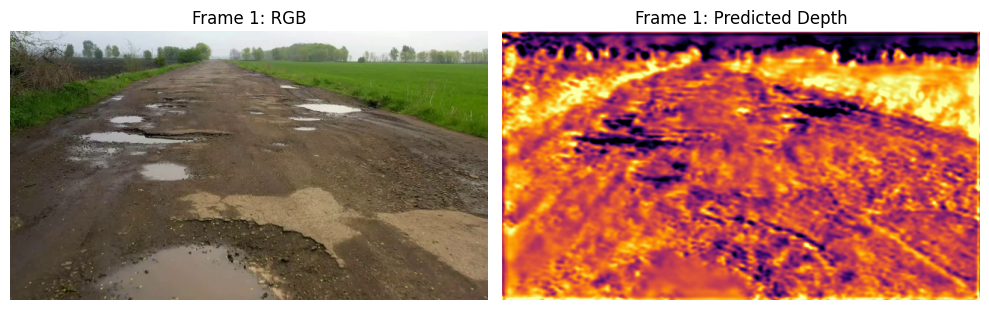

In [39]:
import subprocess
from pathlib import Path

src_mp4 = Path("/content/Yannotated.mp4")
clean_mp4 = Path("/content/Yannotated_h264.mp4")

cmd = [
    "ffmpeg", "-y",
    "-i", str(src_mp4),
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "-crf", "20",
    "-preset", "fast",
    "-an",
    str(clean_mp4),
]
proc = subprocess.run(cmd, capture_output=True, text=True)
print("ffmpeg returncode:", proc.returncode)
if proc.returncode != 0:
    print("ffmpeg stderr:", proc.stderr[-800:])
else:
    print(f"Created clean video: {clean_mp4} ({clean_mp4.stat().st_size / (1024 * 1024):.2f} MB)")
    test_video_inference(str(clean_mp4), "/content/Yannotated_depth.mp4")